## Bulk functional analysis for Control = 10mix and perturbation = 11mix

In [1]:
import pandas as pd
pd.set_option('display.max_rows', 500)

### Import libraries

In [2]:
import decoupler as dc

# Only needed for visualization:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
#import scanpy_helpers as sh
import seaborn as sns
from itertools import zip_longest
from anndata import AnnData
from matplotlib import collections  as mc

### Log TPM

In [3]:
# Log TPM
tpm = "/data/projects/2021/MicrobialMetabolites/bacterial-supernatant/10_rnaseq_pipeline/star_salmon/salmon.merged.gene_tpm.tsv"

tpm = pd.read_csv(tpm, sep="\t")

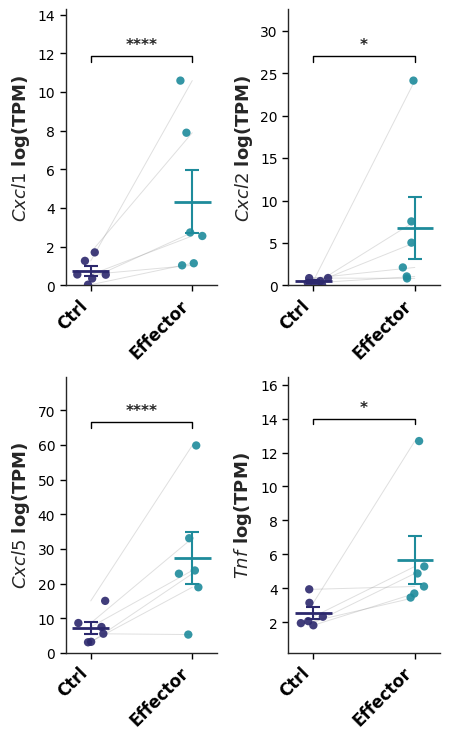

Saved: /data/scratch/kvalem/projects/2021/prj-honda_og/01_bacterial_products/001_organoid_bacterial_supernatant/results/paired_boxplots_Ctrl_vs_Effector_dynamicFDR.svg


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1) Load data
# -----------------------------
tpm_path = "/data/projects/2021/MicrobialMetabolites/bacterial-supernatant/10_rnaseq_pipeline/star_salmon/salmon.merged.gene_tpm.tsv"
deg_path = "/data/projects/2021/MicrobialMetabolites/bacterial-supernatant/20_deseq2icbi/paired_grp/deseq2_11mix_vs_10mix/redo_deseq2_04032025/11mix_10mix_IHWallGenes.tsv"

tpm = pd.read_csv(tpm_path, sep="\t")
deg = pd.read_csv(deg_path, sep="\t")

# -----------------------------
# 2) Settings & Dynamic FDR Extraction
# -----------------------------
genes = ["Cxcl1", "Cxcl2", "Cxcl5", "Tnf"]

# Column names in your files
tpm_gene_col = "gene_name"
deg_gene_col = "gene_name"  # change if different in deg table (e.g., "Gene", "gene_id")
deg_fdr_col = "padj"       # change if named differently (e.g., "p_adj", "adj.P.Val")

# Extract FDR values from DEG table automatically
fdr_values = (
    deg[deg[deg_gene_col].isin(genes)]
    .drop_duplicates(subset=[deg_gene_col])
    .set_index(deg_gene_col)[deg_fdr_col]
    .to_dict()
)

cond_order = ["10mix", "11mix"]
cond_label_map = {"10mix": "Ctrl", "11mix": "Effector"}
out_svg = "/data/scratch/kvalem/projects/2021/prj-honda_og/01_bacterial_products/001_organoid_bacterial_supernatant/results/paired_boxplots_Ctrl_vs_Effector_dynamicFDR.svg"
out_png = "/data/scratch/kvalem/projects/2021/prj-honda_og/01_bacterial_products/001_organoid_bacterial_supernatant/results/paired_boxplots_Ctrl_vs_Effector_dynamicFDR.png"
# -----------------------------
# 3) Build long dataframe
# -----------------------------
sample_cols = [c for c in tpm.columns if c.startswith("mHCO") and "_" in c]

df = tpm[[tpm_gene_col] + sample_cols].copy()
df = df[df[tpm_gene_col].isin(genes)].copy()

long = df.melt(
    id_vars=tpm_gene_col,
    value_vars=sample_cols,
    var_name="sample",
    value_name="log_tpm"
)

long[["replicate", "condition"]] = long["sample"].str.rsplit("_", n=1, expand=True)
long = long[long["condition"].isin(cond_order)].copy()

# Keep only true pairs per gene
paired_counts = (
    long.groupby([tpm_gene_col, "replicate"])["condition"]
        .nunique()
        .reset_index(name="n_cond")
)
paired_reps = paired_counts.loc[paired_counts["n_cond"] == len(cond_order), [tpm_gene_col, "replicate"]]
long = long.merge(paired_reps, on=[tpm_gene_col, "replicate"], how="inner")

long["condition"] = pd.Categorical(long["condition"], categories=cond_order, ordered=True)
long["condition_label"] = long["condition"].map(cond_label_map)

# -----------------------------
# 4) Formatting helpers
# -----------------------------
def p_to_stars(p_val):
    if pd.isna(p_val):
        return "ns"
    if p_val < 0.0001:
        return "****"
    elif p_val < 0.001:
        return "***"
    elif p_val < 0.01:
        return "**"
    elif p_val < 0.05:
        return "*"
    return "ns"

# -----------------------------
# 5) Plot: Prism style (2 rows x 2 columns)
# -----------------------------
sns.set_style("ticks")
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans"]

palette = {
    "Ctrl": "#2c286d",
    "Effector": "#1e8b9b"
}

nrows, ncols = 2, 2
fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(4.6, 7.5),
    sharey=False
)

# Flatten the 2x2 axes array into a 1D array
axes = axes.flatten()

x_tick_labels = [cond_label_map[c] for c in cond_order]

for ax, g in zip(axes, genes):
    gdf = long[long[tpm_gene_col] == g].copy()

    # 1. Strip plot
    sns.stripplot(
        data=gdf,
        x="condition_label",
        y="log_tpm",
        order=x_tick_labels,
        palette=palette,
        hue="condition_label",
        legend=False,
        jitter=0.15,
        size=6,
        alpha=0.9,
        ax=ax,
        zorder=3
    )

    # 2. Mean ± SEM bars
    for i, cond in enumerate(x_tick_labels):
        vals = gdf.loc[gdf["condition_label"] == cond, "log_tpm"].values
        if len(vals) > 0:
            mean_val = np.mean(vals)
            sem_val = np.std(vals, ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
            color = palette[cond]

            ax.errorbar(
                x=i,
                y=mean_val,
                yerr=sem_val,
                fmt="none",
                ecolor=color,
                elinewidth=1.5,
                capsize=5,
                capthick=1.5,
                zorder=2
            )
            ax.hlines(
                y=mean_val,
                xmin=i - 0.18,
                xmax=i + 0.18,
                colors=color,
                linewidth=2.0,
                zorder=4
            )

    # 3. Paired replicate lines
    for rep, sub in gdf.groupby("replicate"):
        sub = sub.sort_values("condition_label")
        if sub["condition_label"].nunique() == 2:
            ax.plot(
                [0, 1],
                sub["log_tpm"].values,
                linewidth=0.7,
                alpha=0.25,
                color="gray",
                zorder=1
            )

    # 4. Y-axis scaling & significance bracket
    y_min_data = gdf["log_tpm"].min()
    y_max_data = gdf["log_tpm"].max()
    y_range = max(y_max_data - y_min_data, 1.0)

    y_bottom = max(0, y_min_data - 0.15 * y_range)
    y_top = y_max_data + 0.35 * y_range
    ax.set_ylim(y_bottom, y_top)

    # Get FDR from DEG file
    gene_fdr = fdr_values.get(g, np.nan)
    annot_text = p_to_stars(gene_fdr)

    bracket_y = y_max_data + 0.12 * y_range
    bracket_h = 0.03 * y_range

    ax.plot([0, 0, 1, 1], 
            [bracket_y - bracket_h, bracket_y, bracket_y, bracket_y - bracket_h], 
            color="black", lw=1.0)
    ax.text(0.5, bracket_y + 0.02 * y_range, annot_text, 
            ha="center", va="bottom", fontsize=11, fontweight="bold")

    # 5. Italicized Gene Name & styling
    ax.set_ylabel(rf"$\it{{{g}}}$ log(TPM)", fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_title("")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(x_tick_labels, rotation=45, ha="right", fontsize=12, fontweight="bold")

    sns.despine(ax=ax, top=True, right=True)
    ax.tick_params(direction="out", length=4, width=1.0, colors="black")
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(1.0)

# Remove unused axes if fewer than 4 genes are provided
for j in range(len(genes), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(out_svg, format="svg", bbox_inches="tight")
plt.savefig(out_png, format="png", dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {out_svg}")